<a href="https://colab.research.google.com/github/jooyongsim/Pendulum_control/blob/main/simulator/bc_swingup_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Behavior Cloning (BC) — 시뮬레이션에서 시연 데이터를 모아 회전형 진자 제어기 학습하기

**목표**: 우리 장비 (STEVAL-EDUKIT01 회전형 도립진자) 의 동정 모델 위에서, 장비의 기존 제어기
(에너지 swing-up + 극점 배치 균형) 를 **선생님(teacher)** 으로 두고 그 행동을 신경망이 흉내 내도록 학습합니다.

| 단계 | 내용 |
|---|---|
| 1 | 시뮬레이터 (장비 동정 모델 + 펌웨어 제약) |
| 2 | 선생님 제어기 |
| 3 | **시연 데이터 수집** — (관측, 선생님 행동) 쌍. 선택: 행동 잡음 주입 (DART) |
| 4 | **BC 학습** — 평균제곱오차 회귀, train / validation 분리 |
| 5 | 시뮬레이터에서 평가 (swing-up, balance) |
| 6 | (선택) DAgger — 학생이 방문한 상태에 선생님 레이블을 붙여 데이터 추가 |
| 7 | `.pt` 저장 → 실제 장비에서 `swing-up/swingup_rl_control.py` 로 실행 |

이 노트북은 **파일 하나로 동작** 합니다 (저장소의 다른 파일이 필요 없음). Colab 에서는 위에서부터 차례로 실행하면 됩니다.
GPU 는 필요 없습니다 (작은 MLP 라 CPU 가 충분히 빠름).

## 0. 설정
아래 값만 바꿔서 실험하면 됩니다.

| 변수 | 뜻 |
|---|---|
| `N_SWINGUP_EPISODES` | swing-up 시연 에피소드 수 (1 개 = 10 s = 500 샘플) |
| `N_BALANCE_EPISODES` | 직립 근처에서 시작하는 시연 에피소드 수 (1 개 = 5 s = 250 샘플) |
| `NOISE_STD` | 데이터 수집 때 **실제로 실행하는** 행동에 더하는 잡음 (레이블은 잡음 없는 선생님 행동). 0 이면 순수 BC |
| `DAGGER_ITERS` | 0 이면 BC 만. 1 이상이면 그 횟수만큼 DAgger 반복 |
| `EPOCHS`, `HIDDEN`, `LR`, `BATCH` | 학습 설정 |

In [21]:
import json
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib
import torch
import torch.nn as nn
import torch.nn.functional as F

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")                         # 스크립트로 실행할 때는 그림을 파일로만 저장
import matplotlib.pyplot as plt

QUICK = os.environ.get("BC_QUICK") == "1"         # 동작 확인용 짧은 실행 (python bc_swingup_colab.py 에서 BC_QUICK=1)

SEED = 0
N_SWINGUP_EPISODES = 6 if QUICK else 60
N_BALANCE_EPISODES = 2 if QUICK else 20
NOISE_STD = 0.1                                  # 행동 잡음 (a 단위, |a| <= 1). 0 = 순수 BC
DAGGER_ITERS = 8 # if QUICK else 0                 # 0 = BC 만
N_DAGGER_EPISODES = 2 if QUICK else 10
EPOCHS = 3 if QUICK else 60
HIDDEN = (128, 128)
LR = 1e-3
BATCH = 256
VAL_FRACTION = 0.1

try:
    HERE = Path(__file__).resolve().parent        # python 스크립트로 실행할 때
except NameError:
    HERE = Path.cwd()                             # Jupyter / Colab (/content)
OUT_DIR = HERE / "bc_results"
OUT_DIR.mkdir(exist_ok=True)
# MODEL_NAME = "rotary_bc_colab" + ("_quick" if QUICK else "")
MODEL_NAME = "rotary_dagger_colab"

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)


def show():
    """노트북이면 그림 표시, 스크립트면 닫기 (파일로는 이미 저장됨)"""
    plt.show() if IN_NOTEBOOK else plt.close("all")


print("torch", torch.__version__, "| output ->", OUT_DIR, "| QUICK" if QUICK else "")

torch 2.11.0+cpu | output -> /content/bc_results 


## 1. 시뮬레이터 — 장비의 동정 모델

$\theta$: 막대 각도 (**직립 = 0**, 매달림 = $\pm\pi$), $\phi$: 팔 각도, $u = \ddot\phi$: 팔 가속도 명령 [rad/s²]
$$
\ddot\theta = \omega_n^2\sin\theta + b\cos\theta\,\ddot\phi + \sin\theta\cos\theta\,\dot\phi^2 - 2\zeta\omega_n\dot\theta - F_c\,\mathrm{sgn}(\dot\theta)
$$

| 상수 | 값 |
|---|---|
| $\omega_n$ | 7.499 rad/s ($\omega_n^2$ = 56.2 s⁻²) |
| $\zeta$ | 0.01172 |
| $b = 3r/2l$ | 0.730 |
| $F_c$ | 0.556 rad/s² (건마찰) |

**펌웨어 제약** (`SwingupController.ino`): $|\ddot\phi| \le 47.1$ rad/s², $|\dot\phi| \le 7.85$ rad/s,
속도가 0.059 rad/s (30 pps) 미만이면 모터가 멈춤. 팔은 $\pm 140°$ 를 넘으면 안 됨 (케이블).

**관측** $o = [\cos\theta, \sin\theta, \dot\theta, \phi, \dot\phi]$, **행동** $a \in [-1, 1]$ → $u = 47.1\,a$,
**제어 주기** 20 ms (50 Hz). 실제 장비 스크립트 (`swingup_rl_control.py`) 와 똑같은 입출력입니다.

In [22]:
G = 9.81
WN, ZETA = 7.499, 0.01172
A_G = WN ** 2                                    # 3g/2l
C_D = 2 * ZETA * WN                              # 점성 감쇠
B_U = 0.730                                      # 3r/2l
L_ROD = 3 * G / (2 * WN ** 2)                    # 0.262 m
F_C = math.radians(2.705) * WN ** 2 * (2 * math.pi / WN) / 4.0   # 건마찰 [rad/s^2]
STEP_RAD = 2 * math.pi / 3200                    # 1/16 마이크로스텝
ACCEL_MAX = 24000 * STEP_RAD                     # 47.1 rad/s^2
SPEED_MAX = 4000 * STEP_RAD                      # 7.85 rad/s
SPEED_MIN = 30 * STEP_RAD                        # 이보다 느리면 모터 정지
DT_PHYS = 0.001                                  # 물리 적분 1 ms (RK4)


def wrap(a):
    """각도를 [-pi, pi) 로"""
    return (a + math.pi) % (2 * math.pi) - math.pi


class RotaryPendulumEnv:
    """obs = [cos th, sin th, th_dot, phi, phi_dot], action a in [-1, 1] -> u = a * ACCEL_MAX.
    task = "swingup" (70%: 매달림 근처, 30%: 무작위 각도에서 시작, 10 s) | "balance" (직립 근처, 5 s)"""

    DT_CTRL = 0.02
    ARM_LIM = math.radians(140)
    FALL = math.radians(30)

    def __init__(self, task="swingup", seed=None, b=B_U):
        self.task, self.b = task, b
        self.rng = np.random.default_rng(seed)
        self.max_steps = int((10.0 if task == "swingup" else 5.0) / self.DT_CTRL)
        self.n_sub = int(round(self.DT_CTRL / DT_PHYS))

    def _deriv(self, th, w, v, u):
        running = abs(v) >= SPEED_MIN
        acc = u if running else 0.0
        phid = v if running else 0.0
        s, c = math.sin(th), math.cos(th)
        dw = A_G * s + self.b * c * acc + s * c * phid ** 2 - C_D * w - F_C * math.tanh(w / 0.01)
        return w, dw, phid, u

    def _obs(self):
        th, w, phi, v = self.x
        phid = v if abs(v) >= SPEED_MIN else 0.0
        return np.array([math.cos(th), math.sin(th), w, phi, phid], np.float32)

    def reset(self, options=None):
        r, o = self.rng, (options or {})
        if self.task == "balance":
            th0 = r.uniform(-0.2, 0.2)
        elif r.random() < 0.7:
            th0 = math.pi + r.uniform(-0.1, 0.1)
        else:
            th0 = r.uniform(-math.pi, math.pi)
        self.x = [o.get("theta0", th0), o.get("theta_dot0", r.uniform(-0.5, 0.5)),
                  o.get("phi0", r.uniform(-0.2, 0.2)), 0.0]
        self.k = 0
        return self._obs()

    def step(self, action):
        a = float(np.clip(np.ravel(action)[0], -1.0, 1.0))
        u = a * ACCEL_MAX
        th, w, phi, v = self.x
        h, d = DT_PHYS, self._deriv
        for _ in range(self.n_sub):                  # RK4, 입력은 20 ms 동안 유지
            k1 = d(th, w, v, u)
            k2 = d(th + h / 2 * k1[0], w + h / 2 * k1[1], v + h / 2 * k1[3], u)
            k3 = d(th + h / 2 * k2[0], w + h / 2 * k2[1], v + h / 2 * k2[3], u)
            k4 = d(th + h * k3[0], w + h * k3[1], v + h * k3[3], u)
            th += h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
            w += h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
            phi += h / 6 * (k1[2] + 2 * k2[2] + 2 * k3[2] + k4[2])
            v += h / 6 * (k1[3] + 2 * k2[3] + 2 * k3[3] + k4[3])
            v = max(-SPEED_MAX, min(SPEED_MAX, v))   # 펌웨어 속도 제한
        self.x = [wrap(th), w, phi, v]
        self.k += 1
        failed = abs(phi) > self.ARM_LIM or (self.task == "balance" and abs(self.x[0]) > self.FALL)
        return self._obs(), failed, self.k >= self.max_steps, u

## 2. 선생님 제어기 — 장비의 에너지 swing-up + 극점 배치 균형

**swing-up** (에너지 $E = \tfrac12\dot\theta^2 + \omega_n^2(\cos\theta - 1)$, 직립 정지 = 0):
$$
u = u_{pump}\cdot\mathrm{clip}\big(k_E(E_{target} - E), 0, 1\big)\cdot\mathrm{sgn}(\dot\theta\cos\theta) - k_{da}\dot\phi - k_{pa}\phi
$$
**균형** ($|\theta| < 20°$, $|\dot\theta| < 4$ rad/s): $u = -K[\theta, \dot\theta, \phi, \dot\phi]^\top$,
극점 $-6\pm6j,\ -1.5\pm1j$ 로 배치한 이득 (장비와 같음).

장비 제어기에는 상태 기계 (swing → catch → balance) 가 있지만, 여기서는 **현재 상태만 보고 행동을 정하는** 버전입니다.
그래야 임의의 상태에서 정답 행동을 줄 수 있습니다 (DAgger 와 잡음 주입에 필요).

In [23]:
def place4(poles=(-6 + 6j, -6 - 6j, -1.5 + 1j, -1.5 - 1j), b=B_U):
    """Ackermann 공식: u = -K [th, th', phi, phi'] 의 폐루프 극점을 poles 로"""
    A = np.array([[0, 1, 0, 0], [A_G, -C_D, 0, 0], [0, 0, 0, 1], [0, 0, 0, 0]], float)
    B = np.array([[0], [b], [0], [1]], float)
    ctrb = np.hstack([np.linalg.matrix_power(A, i) @ B for i in range(4)])
    phi = np.zeros_like(A)
    for c in np.real(np.poly(poles)):
        phi = phi @ A + c * np.eye(4)
    return np.linalg.solve(ctrb.T, np.eye(4)[:, -1]) @ phi


K_TEACHER = place4()
TP = dict(pump=30.0, ke=0.3, etarget=1.0, kpa=3.0, kda=5.0, catch_deg=20.0, catch_w=4.0)
print("K =", np.round(K_TEACHER, 2))


def teacher_action(obs):
    """obs -> a in [-1, 1]"""
    c, s, w, phi, phid = (float(v) for v in obs)
    th = math.atan2(s, c)
    if abs(th) < math.radians(TP["catch_deg"]) and abs(w) < TP["catch_w"]:
        u = -float(K_TEACHER @ np.array([th, w, phi, phid]))
    else:
        E = 0.5 * w * w + A_G * (c - 1.0)
        scale = min(1.0, max(0.0, TP["ke"] * (TP["etarget"] - E)))
        sgn = 1.0 if w * c > 0 else -1.0
        u = TP["pump"] * scale * sgn - TP["kda"] * phid - TP["kpa"] * phi
    return np.array([np.clip(u / ACCEL_MAX, -1.0, 1.0)], np.float32)

K = [236.23  26.54  -4.16  -4.55]


### 평가 도구
- `eval_swingup`: 매달린 상태 3 가지 (180, 177, 186°) 에서 10 s. `t_up` = 처음 직립 ±10° 에 들어간 시각,
  `hold` = 마지막 2 s 동안 직립 비율 (1.0 이 만점)
- `eval_balance`: 직립 근처 4 가지 (5, −8, 11, −3°) 에서 5 s. `falls` = 넘어지거나 팔 한계를 넘은 횟수

teacher: swing-up t_up [2.6 2.7 2.5] s, hold 1.00, arm-limit 0/3 | balance falls 0/4 (0.3 s)


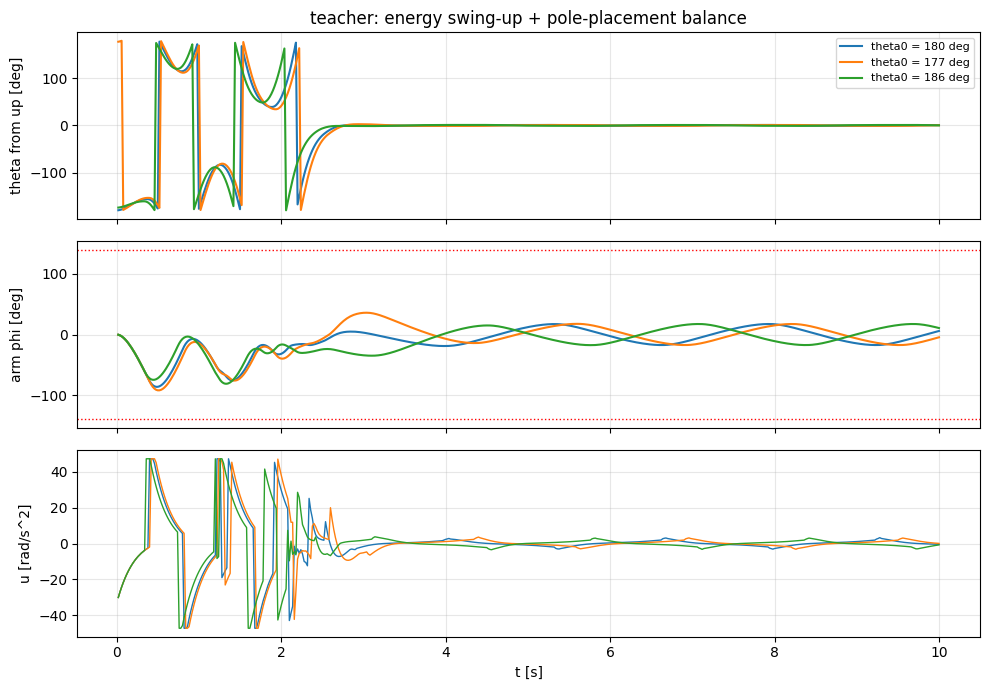

In [24]:
def rollout(policy, task, theta0, seconds=None):
    env = RotaryPendulumEnv(task)
    if seconds:
        env.max_steps = int(seconds / env.DT_CTRL)
    obs = env.reset(options=dict(theta0=theta0, theta_dot0=0.0, phi0=0.0))
    log = {k: [] for k in ("t", "th", "phi", "u")}
    done = failed = False
    while not done:
        obs, failed, trunc, u = env.step(policy(obs))
        done = failed or trunc
        for k, v in zip(log, (env.k * env.DT_CTRL, env.x[0], env.x[2], u)):
            log[k].append(v)
    log = {k: np.array(v) for k, v in log.items()}
    log["failed"] = failed
    return log


SWINGUP_STARTS = [math.pi, math.pi - 0.05, math.pi + 0.1]
BALANCE_STARTS = [math.radians(d) for d in (5, -8, 11, -3)]


def eval_swingup(policy):
    res = []
    for th0 in SWINGUP_STARTS:
        lg = rollout(policy, "swingup", th0)
        up = np.abs(lg["th"]) < math.radians(10)
        t_up = lg["t"][np.argmax(up)] if up.any() else None
        hold = 0.0 if lg["failed"] else up[-100:].mean()
        res.append((t_up, hold, lg["failed"]))
    return dict(t_up=[r[0] for r in res], hold=float(np.mean([r[1] for r in res])),
                arm_limit=int(sum(r[2] for r in res)))


def eval_balance(policy):
    return dict(falls=int(sum(rollout(policy, "balance", th0)["failed"] for th0 in BALANCE_STARTS)))


def fmt(ev_s, ev_b):
    t = " ".join("--" if x is None else f"{x:.1f}" for x in ev_s["t_up"])
    return (f"swing-up t_up [{t}] s, hold {ev_s['hold']:.2f}, arm-limit {ev_s['arm_limit']}/3 | "
            f"balance falls {ev_b['falls']}/4")


def plot_rotary(logs, title, fname):
    fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
    for name, lg in logs.items():
        ax[0].plot(lg["t"], np.degrees(lg["th"]), label=name + ("  (failed)" if lg["failed"] else ""))
        ax[1].plot(lg["t"], np.degrees(lg["phi"]))
        ax[2].plot(lg["t"], lg["u"], lw=1)
    ax[0].set_ylabel("theta from up [deg]"); ax[0].legend(fontsize=8, loc="upper right")
    ax[1].set_ylabel("arm phi [deg]")
    for s in (1, -1):
        ax[1].axhline(s * 140, color="r", ls=":", lw=1)
    ax[2].set_ylabel("u [rad/s^2]"); ax[2].set_xlabel("t [s]")
    for a_ in ax:
        a_.grid(alpha=.3)
    ax[0].set_title(title); plt.tight_layout()
    fig.savefig(OUT_DIR / f"{fname}.png", dpi=110)
    show()


t0 = time.time()
print("teacher:", fmt(eval_swingup(teacher_action), eval_balance(teacher_action)), f"({time.time() - t0:.1f} s)")
plot_rotary({f"theta0 = {math.degrees(t):.0f} deg": rollout(teacher_action, "swingup", t) for t in SWINGUP_STARTS},
            "teacher: energy swing-up + pole-placement balance", "teacher_swingup")

## 3. 시연 데이터 수집

선생님이 환경을 직접 움직이며 **(관측 $o$, 선생님 행동 $a^*(o)$)** 쌍을 모읍니다.

**행동 잡음 주입 (DART, Laskey et al. 2017)** — 순수 BC 의 약점은 *선생님이 간 상태에서만* 배운다는 것입니다
(학생이 조금만 벗어나면 배운 적 없는 상태 → 오차 누적, **covariate shift**).
수집할 때 **실제로 실행하는 행동** 에만 잡음을 더하면 ($a_{exec} = a^* + \epsilon$), 선생님 궤적 *주변* 의 상태도 방문하게 되고,
그 상태들에서 **잡음 없는 선생님 행동 $a^*(o)$** 를 레이블로 저장합니다. `NOISE_STD = 0` 이면 순수 BC 입니다.

데이터는 `bc_results/bc_dataset.npz` 로 저장됩니다.

In [25]:
def collect(task, n_episodes, act_fn, seed, noise_std=0.0):
    """act_fn (+잡음) 으로 환경을 움직이며 방문한 관측과 그 관측에서의 teacher 행동(레이블) 수집"""
    env = RotaryPendulumEnv(task, seed=seed)
    rng = np.random.default_rng(seed + 1000)
    O, A, n_fail = [], [], 0
    for _ in range(n_episodes):
        obs, done = env.reset(), False
        while not done:
            a_star = teacher_action(obs)
            O.append(obs); A.append(a_star)
            a_exec = act_fn(obs) + noise_std * rng.standard_normal(1)
            obs, failed, trunc, _ = env.step(a_exec)
            done = failed or trunc
        n_fail += failed
    return np.array(O, np.float32), np.array(A, np.float32), n_fail


t0 = time.time()
O_sw, A_sw, f_sw = collect("swingup", N_SWINGUP_EPISODES, teacher_action, SEED, NOISE_STD)
O_bal, A_bal, f_bal = collect("balance", N_BALANCE_EPISODES, teacher_action, SEED + 1, NOISE_STD)
O_all, A_all = np.concatenate([O_sw, O_bal]), np.concatenate([A_sw, A_bal])
np.savez_compressed(OUT_DIR / "bc_dataset.npz", obs=O_all, act=A_all)
print(f"collected {len(O_all)} samples ({len(O_sw)} swing-up + {len(O_bal)} balance) in {time.time() - t0:.1f} s | "
      f"episodes ended early: swing-up {f_sw}/{N_SWINGUP_EPISODES}, balance {f_bal}/{N_BALANCE_EPISODES}")

collected 33847 samples (28847 swing-up + 5000 balance) in 4.1 s | episodes ended early: swing-up 3/60, balance 0/20


### 데이터 분포 확인
막대 각도 $\theta$ 가 매달림 (±180°) 부터 직립 (0°) 까지 고르게 있어야 하고, 행동 $a$ 는 swing-up 에서 ±0.6 근처
(펌핑 30 rad/s²), 균형에서 0 근처에 몰려 있습니다.

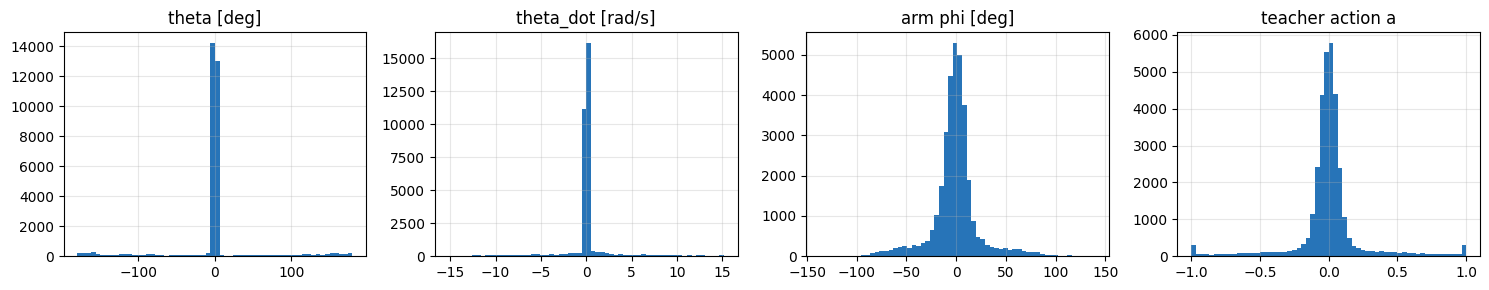

In [26]:
th_all = np.degrees(np.arctan2(O_all[:, 1], O_all[:, 0]))
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a_, (x, name) in zip(ax, ((th_all, "theta [deg]"), (O_all[:, 2], "theta_dot [rad/s]"),
                              (np.degrees(O_all[:, 3]), "arm phi [deg]"), (A_all[:, 0], "teacher action a"))):
    a_.hist(x, bins=60, color="#2774B8"); a_.set_title(name); a_.grid(alpha=.3)
plt.tight_layout(); fig.savefig(OUT_DIR / "dataset_hist.png", dpi=110); show()

## 4. BC 학습 — 지도학습 회귀
정책 $\pi_\theta(o) = \tanh(f_\theta(o))$ 가 선생님 행동을 맞히도록 평균제곱오차를 최소화합니다.
$$
\min_\theta\ \frac{1}{N}\sum_i \big(\pi_\theta(o_i) - a^*_i\big)^2
$$
데이터의 10% 를 검증용으로 떼어 두고, **검증 오차가 가장 작은 epoch 의 가중치** 를 저장합니다.

> 네트워크 구조 (`net` = Linear-ReLU-Linear-ReLU-Linear, 출력에 tanh) 를 바꾸지 마세요. 실제 장비 스크립트
> `swingup_rl_control.py --kind bc` 가 이 구조 (`net.0`, `net.2`, `net.4`) 를 그대로 읽습니다. 은닉층 크기는 바꿔도 됩니다.

epoch   1/60 | train mse 0.03503 | val mse 0.02841 |   0.1 s
epoch   7/60 | train mse 0.01333 | val mse 0.01322 |   1.0 s
epoch  13/60 | train mse 0.00868 | val mse 0.00940 |   1.9 s
epoch  19/60 | train mse 0.00700 | val mse 0.00839 |   3.1 s
epoch  25/60 | train mse 0.00604 | val mse 0.00697 |   4.1 s
epoch  31/60 | train mse 0.00512 | val mse 0.00618 |   5.0 s
epoch  37/60 | train mse 0.00467 | val mse 0.00614 |   5.9 s
epoch  43/60 | train mse 0.00417 | val mse 0.00559 |   6.8 s
epoch  49/60 | train mse 0.00388 | val mse 0.00556 |   7.7 s
epoch  55/60 | train mse 0.00375 | val mse 0.00543 |   8.5 s
epoch  60/60 | train mse 0.00370 | val mse 0.00542 |   9.3 s


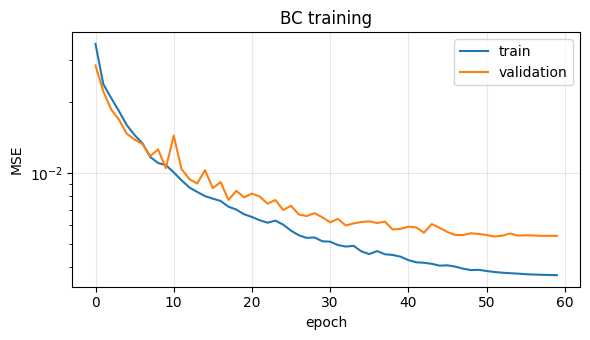

In [27]:
def mlp(inp, out, hidden):
    layers, d = [], inp
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU()]
        d = h
    layers.append(nn.Linear(d, out))
    return nn.Sequential(*layers)


class BCPolicy(nn.Module):
    def __init__(self, hidden=HIDDEN):
        super().__init__()
        self.net = mlp(5, 1, hidden)

    def forward(self, s):
        return torch.tanh(self.net(s))

    @torch.no_grad()
    def act(self, obs):
        return self(torch.as_tensor(obs, dtype=torch.float32)).numpy()


def train_bc(O, A, epochs=EPOCHS, lr=LR, batch=BATCH, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(O))
    n_val = int(len(O) * VAL_FRACTION)
    va, tr = idx[:n_val], idx[n_val:]
    Ot, At = torch.as_tensor(O[tr]), torch.as_tensor(A[tr])
    Ov, Av = torch.as_tensor(O[va]), torch.as_tensor(A[va])
    pi = BCPolicy()
    opt = torch.optim.Adam(pi.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist, best, best_state = {"train": [], "val": []}, float("inf"), None
    t0 = time.time()
    for ep in range(epochs):
        perm = torch.randperm(len(Ot))
        tot = 0.0
        for i in range(0, len(perm), batch):
            j = perm[i:i + batch]
            loss = F.mse_loss(pi(Ot[j]), At[j])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(j)
        sched.step()
        with torch.no_grad():
            val = F.mse_loss(pi(Ov), Av).item()
        hist["train"].append(tot / len(Ot)); hist["val"].append(val)
        if val < best:
            best, best_state = val, {k: v.clone() for k, v in pi.state_dict().items()}
        if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
            print(f"epoch {ep + 1:3d}/{epochs} | train mse {hist['train'][-1]:.5f} | val mse {val:.5f} | "
                  f"{time.time() - t0:5.1f} s", flush=True)
    pi.load_state_dict(best_state)
    return pi, hist


bc_policy, bc_hist = train_bc(O_all, A_all)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(bc_hist["train"], label="train"); ax.semilogy(bc_hist["val"], label="validation")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_title("BC training"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); fig.savefig(OUT_DIR / "bc_loss.png", dpi=110); show()

## 5. 시뮬레이터에서 평가
**회귀 오차가 작다고 제어를 잘하는 것은 아닙니다.** 학생이 직접 진자를 움직이게 해서 확인합니다.

teacher: swing-up t_up [2.6 2.7 2.5] s, hold 1.00, arm-limit 0/3 | balance falls 0/4
BC     : swing-up t_up [2.7 2.7 2.7] s, hold 0.69, arm-limit 0/3 | balance falls 1/4


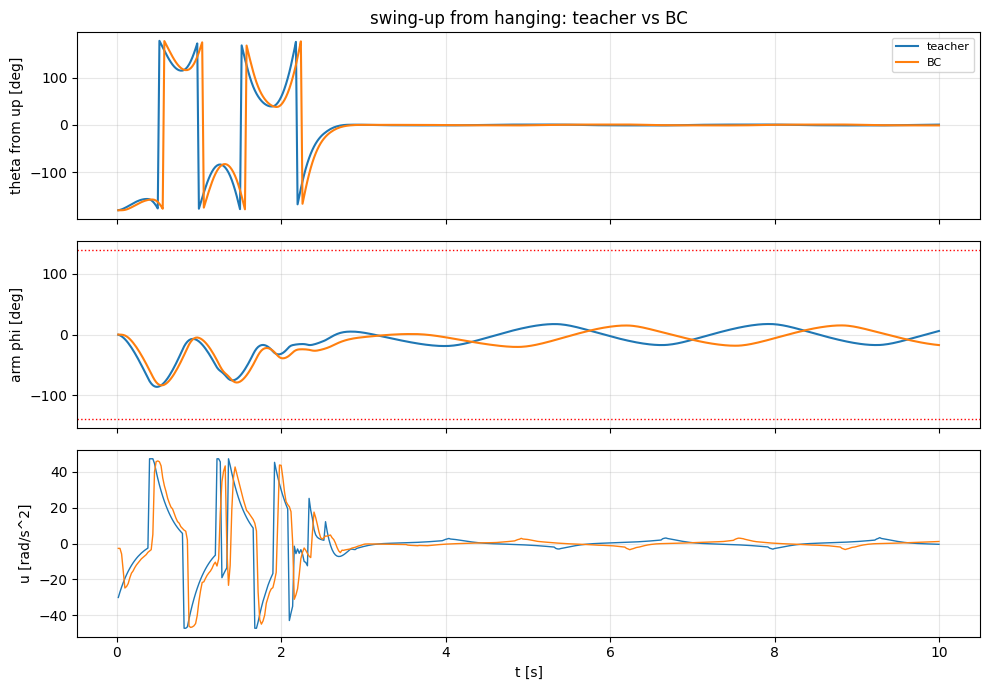

In [28]:
ev_bc = (eval_swingup(bc_policy.act), eval_balance(bc_policy.act))
print("teacher:", fmt(eval_swingup(teacher_action), eval_balance(teacher_action)))
print("BC     :", fmt(*ev_bc))
plot_rotary({"teacher": rollout(teacher_action, "swingup", math.pi),
             "BC": rollout(bc_policy.act, "swingup", math.pi)},
            "swing-up from hanging: teacher vs BC", "bc_swingup_response")

## 6. (선택) DAgger — 학생이 방문한 상태에서 선생님에게 묻기
`DAGGER_ITERS > 0` 일 때만 실행됩니다.
```
반복:  학생 pi 로 환경을 움직임  ->  방문한 상태 o 마다 선생님 행동 a*(o) 를 레이블로  ->  데이터에 추가  ->  재학습
```
BC 가 시뮬레이터에서도 실패하면 (balance 가 넘어지거나 swing-up 뒤 유지하지 못하면) `DAGGER_ITERS = 5~8` 로 켜 보세요.
이전 튜토리얼 (v3) 에서는 순수 BC 가 4/4 넘어졌고, DAgger 8 회로 선생님 수준이 되었습니다.

In [ ]:
final_policy, final_tag = bc_policy, "bc"
if DAGGER_ITERS > 0:
    O_d, A_d = O_all, A_all
    pi = bc_policy
    for it in range(1, DAGGER_ITERS + 1):
        O2, A2, _ = collect("swingup", N_DAGGER_EPISODES, pi.act, SEED + 100 + it)
        O3, A3, _ = collect("balance", max(1, N_DAGGER_EPISODES // 3), pi.act, SEED + 200 + it)
        O_d, A_d = np.concatenate([O_d, O2, O3]), np.concatenate([A_d, A2, A3])
        pi, h = train_bc(O_d, A_d, verbose=False)
        print(f"DAgger {it}/{DAGGER_ITERS} | data {len(O_d)} | val mse {min(h['val']):.5f} | "
              + fmt(eval_swingup(pi.act), eval_balance(pi.act)), flush=True)
    final_policy, final_tag = pi, f"dagger{DAGGER_ITERS}"
    np.savez_compressed(OUT_DIR / "bc_dataset_dagger.npz", obs=O_d, act=A_d)
    plot_rotary({"teacher": rollout(teacher_action, "swingup", math.pi),
                 "BC": rollout(bc_policy.act, "swingup", math.pi),
                 "DAgger": rollout(final_policy.act, "swingup", math.pi)},
                "swing-up from hanging: teacher vs BC vs DAgger", "dagger_swingup_response")

DAgger 1/8 | data 38901 | val mse 0.00523 | swing-up t_up [2.9 2.6 2.6] s, hold 0.67, arm-limit 1/3 | balance falls 0/4


## 7. 저장
- `bc_results/rotary_bc_colab.pt` : 최종 정책 가중치 (`state_dict`)
- `bc_results/rotary_bc_colab.json` : 설정, 학습 곡선, 평가 결과

**실제 장비에서 실행** (저장소의 `Pendulum_control` 폴더에서):
```
python swing-up/swingup_rl_control.py --model simulator/rl_models/rotary_bc_colab.pt --kind bc
```
(`.pt` 파일을 `simulator/rl_models/` 에 넣은 경우. 먼저 `--sim --yes` 를 붙여 보드 없이 확인하세요.)

In [ ]:
pt_path = OUT_DIR / f"{MODEL_NAME}.pt"
torch.save(final_policy.state_dict(), pt_path)
ev_final = (eval_swingup(final_policy.act), eval_balance(final_policy.act))
meta = dict(policy=final_tag, obs="[cos th, sin th, th_dot, phi, phi_dot], th = 0 upright",
            action="a = tanh(net(obs)) in [-1, 1], u = a * 47.12 rad/s^2, 50 Hz",
            config=dict(seed=SEED, n_swingup=N_SWINGUP_EPISODES, n_balance=N_BALANCE_EPISODES, noise_std=NOISE_STD,
                        dagger_iters=DAGGER_ITERS, epochs=EPOCHS, hidden=list(HIDDEN), lr=LR, batch=BATCH),
            n_samples=int(len(O_all)), train_mse=bc_hist["train"], val_mse=bc_hist["val"],
            eval=dict(swingup=ev_final[0], balance=ev_final[1]))
pt_path.with_suffix(".json").write_text(json.dumps(meta, indent=1, default=float))
print("saved", pt_path, "|", fmt(*ev_final))

if "google.colab" in sys.modules:              # Colab: 파일 내려받기
    from google.colab import files
    files.download(str(pt_path)); files.download(str(pt_path.with_suffix(".json")))